## Import Libraries

In [1]:
import pandas as pd #Import necessary libraries 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline 

In [2]:
import warnings #Ignore warnings
warnings.filterwarnings('ignore')

## Import Dataset

In [3]:
data="product.csv" #Read data into a dataframe
df=pd.read_csv(data, header=None)

## Exploratory Data Analysis (EDA)

In [5]:
df.shape

(5000, 14)

In [6]:
df.head()

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,Order_ID,Order_Date,Customer_Name,City,State,Region,Country,Category,Sub_Category,Product_Name,Quantity,Unit_Price,Revenue,Profit
1,1,8/23/2023,Bianca Brown,Jackson,Mississippi,South,United States,Accessories,Small Electronics,Phone Case,3,201.01,603.03,221.49
2,2,12/20/2024,Jared Edwards,Grand Rapids,Michigan,Centre,United States,Accessories,Small Electronics,Charging Cable,4,74.3,297.2,97.09
3,3,1/29/2024,Susan Valdez,Minneapolis,Minnesota,Centre,United States,Clothing & Apparel,Sportswear,Nike Air Force 1,1,68.19,68.19,25.47
4,4,11/29/2024,Tina Williams,Tallahassee,Florida,South,United States,Clothing & Apparel,Sportswear,Adidas Tracksuit,3,209.64,628.92,231.38


In [8]:
col_names=['Order_ID','Order_Date','Customer_Name','City','State','Region','Country','Category','Sub_Category','Product_Name','Quantity','Unit_Price','Revenue','Profit,'] #Rename column names 
df.columns=col_names
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_Name', 'City', 'State', 'Region',
       'Country', 'Category', 'Sub_Category', 'Product_Name', 'Quantity',
       'Unit_Price', 'Revenue', 'Profit,'],
      dtype='object')

In [9]:
df = df.drop(index=0).reset_index(drop=True) #dropping unnecessary 0th cell
df.head()

,Order_ID,Order_Date,Customer_Name,City,State,Region,Country,Category,Sub_Category,Product_Name,Quantity,Unit_Price,Revenue,"Profit,"
0,1,8/23/2023,Bianca Brown,Jackson,Mississippi,South,United States,Accessories,Small Electronics,Phone Case,3,201.01,603.03,221.49
1,2,12/20/2024,Jared Edwards,Grand Rapids,Michigan,Centre,United States,Accessories,Small Electronics,Charging Cable,4,74.3,297.2,97.09
2,3,1/29/2024,Susan Valdez,Minneapolis,Minnesota,Centre,United States,Clothing & Apparel,Sportswear,Nike Air Force 1,1,68.19,68.19,25.47
3,4,11/29/2024,Tina Williams,Tallahassee,Florida,South,United States,Clothing & Apparel,Sportswear,Adidas Tracksuit,3,209.64,628.92,231.38
4,5,9/21/2023,Catherine Gordon,Baltimore,Maryland,East,United States,Accessories,Bags,Backpack,1,216.63,216.63,42.46


In [10]:
# Drop irrelevant columns
df = df.drop(columns=[
    'Order_ID',
    'Customer_Name', 
    'Region',
    'Country',
    'Sub_Category',
    'Product_Name'
])

# Verify what's left
print(df.columns.tolist())
print(f"\nRemaining columns: {len(df.columns)}")

['Order_Date', 'City', 'State', 'Category', 'Quantity', 'Unit_Price', 'Revenue', 'Profit,']

Remaining columns: 8


In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4999 entries, 0 to 4998
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Order_Date  4999 non-null   object
 1   City        4999 non-null   object
 2   State       4999 non-null   object
 3   Category    4999 non-null   object
 4   Quantity    4999 non-null   object
 5   Unit_Price  4999 non-null   object
 6   Revenue     4999 non-null   object
 7   Profit,     4999 non-null   object
dtypes: object(8)
memory usage: 312.6+ KB


In [15]:
col_names=['Order_Date', 'City', 'State', 'Category', 'Quantity', 'Unit_Price',
       'Revenue', 'Profit,'] 
for col in col_names:
    print(df[col].value_counts())

Order_Date
11/13/2023    36
11/3/2023     35
11/1/2024     31
11/8/2024     31
11/29/2024    29
              ..
2/13/2024      1
3/28/2024      1
2/19/2024      1
2/24/2024      1
7/24/2024      1
Name: count, Length: 725, dtype: int64
City
Burlington      86
Nashua          86
Philadelphia    81
Augusta         80
Jersey City     80
                ..
Orlando         20
Baton Rouge     20
Nashville       20
Richmond        19
Knoxville       15
Name: count, Length: 108, dtype: int64
State
California        251
Arizona           244
New Hampshire     163
Vermont           159
Pennsylvania      156
Connecticut       154
Massachusetts     152
New Jersey        146
Delaware          138
Ohio              138
Florida           136
Alabama           135
Illinois          130
Maryland          128
Texas             125
New York          124
South Dakota      120
Wisconsin         113
New Mexico        110
Michigan          106
Wyoming           105
Kansas            102
Nevada            10

In [16]:
# Function to remove outliers for all numeric columns
def remove_outliers(df):
    # Iterate through each numeric column
    for col in df.select_dtypes(include=['float64', 'int64']):
        Q1 = df[col].quantile(0.25)  # First quartile
        Q3 = df[col].quantile(0.75)  # Third quartile
        IQR = Q3 - Q1  # Interquartile range
        
        # Define outlier bounds
        lower_limit = Q1 - 1.5 * IQR
        upper_limit = Q3 + 1.5 * IQR
        
        # Filter out rows where the column value is outside the outlier bounds
        df = df[(df[col] >= lower_limit) & (df[col] <= upper_limit)]
        
    return df

# Remove outliers from the entire dataset
df = remove_outliers(df)

# Display the cleaned DataFrame
print(df)

      Order_Date           City        State            Category Quantity  \
0      8/23/2023        Jackson  Mississippi         Accessories        3   
1     12/20/2024   Grand Rapids     Michigan         Accessories        4   
2      1/29/2024    Minneapolis    Minnesota  Clothing & Apparel        1   
3     11/29/2024    Tallahassee      Florida  Clothing & Apparel        3   
4      9/21/2023      Baltimore     Maryland         Accessories        1   
...          ...            ...          ...                 ...      ...   
4994   9/10/2023     Burlington      Vermont    Home & Furniture        1   
4995  12/20/2023    New Orleans    Louisiana    Home & Furniture        1   
4996   6/23/2024       St. Paul    Minnesota  Clothing & Apparel        3   
4997   12/1/2023  Oklahoma City     Oklahoma    Home & Furniture        1   
4998   2/25/2023         Newark   New Jersey         Electronics        2   

     Unit_Price Revenue Profit,  
0        201.01  603.03  221.49  
1      


OUTPUT 2: PRODUCT ANALYSIS BY CATEGORY (FSN Analysis)

=== Category Analysis (Sorted by Quantity Sold) ===
             Category  total_quantity_sold  total_revenue  total_profit  \
1  Clothing & Apparel                 2970      696190.30     229061.22   
2         Electronics                 2414     1456902.02     203576.00   
3    Home & Furniture                 2305     1192507.82     276874.31   
0         Accessories                 1570      239816.90      82411.79   

   total_orders  avg_profit_margin  velocity  
1          1581          32.700864  1.878558  
2          1264          13.979879  1.909810  
3          1279          23.269707  1.802189  
0           875          34.129624  1.794286  

1. FAST-MOVING CATEGORIES (Top 3 by Quantity Sold)
             Category  total_quantity_sold  total_revenue  total_profit  \
1  Clothing & Apparel                 2970      696190.30     229061.22   
2         Electronics                 2414     1456902.02     203576.00   
3   

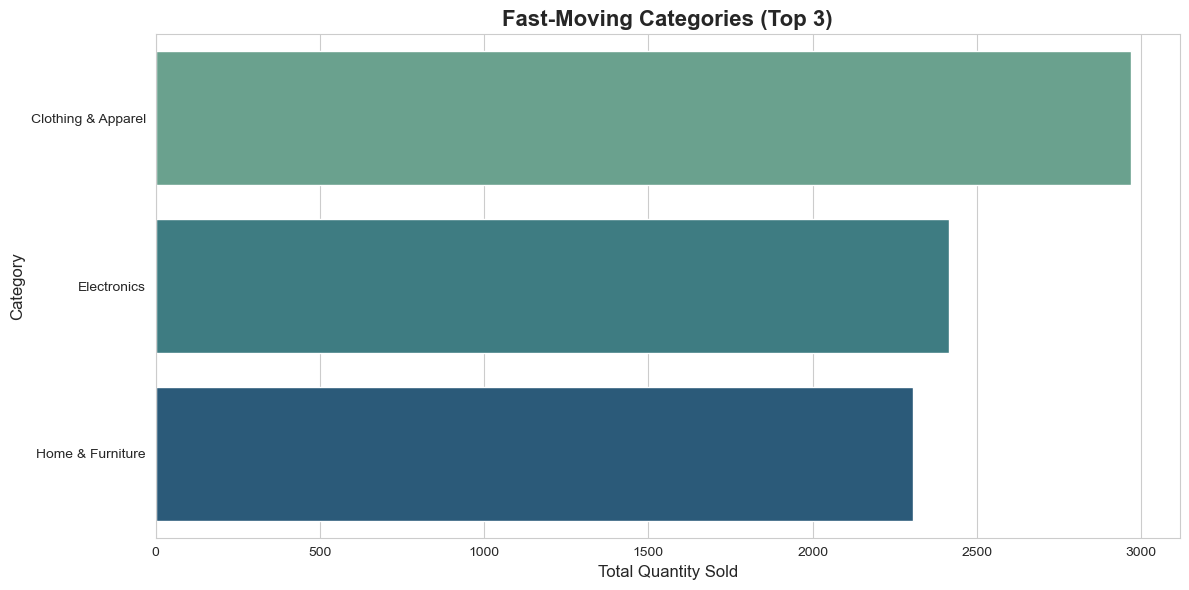

In [34]:
# ========================================
# OUTPUT 2: Product Analysis by Category
# ========================================
print("\n" + "="*70)
print("OUTPUT 2: PRODUCT ANALYSIS BY CATEGORY (FSN Analysis)")
print("="*70)

# Aggregate by Category
category_analysis = df.groupby('Category').agg(
    total_quantity_sold=('Quantity', 'sum'),
    total_revenue=('Revenue', 'sum'),
    total_profit=('Profit', 'sum'),
    total_orders=('Order_Date', 'count'),
    avg_profit_margin=('profit_margin', 'mean')
).reset_index()

# Calculate sales velocity (quantity per order as a proxy for movement speed)
category_analysis['velocity'] = category_analysis['total_quantity_sold'] / category_analysis['total_orders']

# Sort by quantity to find fast-moving categories
category_analysis = category_analysis.sort_values('total_quantity_sold', ascending=False)

print("\n=== Category Analysis (Sorted by Quantity Sold) ===")
print(category_analysis)

# ========================================
# 1. Fast-Moving Categories (Top 3 by Quantity)
# ========================================
print("\n" + "="*70)
print("1. FAST-MOVING CATEGORIES (Top 3 by Quantity Sold)")
print("="*70)

fast_moving = category_analysis.head(3)
print(fast_moving)

plt.figure(figsize=(12, 6))
sns.barplot(data=fast_moving, x='total_quantity_sold', y='Category', 
            palette='crest', orient='h')
plt.title('Fast-Moving Categories (Top 3)', fontsize=16, fontweight='bold')
plt.xlabel('Total Quantity Sold', fontsize=12)
plt.ylabel('Category', fontsize=12)
plt.tight_layout()
plt.show()



2. DEAD STOCK CATEGORIES (Bottom 3 by Quantity Sold)
           Category  total_quantity_sold  total_revenue  total_profit  \
2       Electronics                 2414     1456902.02     203576.00   
3  Home & Furniture                 2305     1192507.82     276874.31   
0       Accessories                 1570      239816.90      82411.79   

   total_orders  avg_profit_margin  velocity  
2          1264          13.979879  1.909810  
3          1279          23.269707  1.802189  
0           875          34.129624  1.794286  


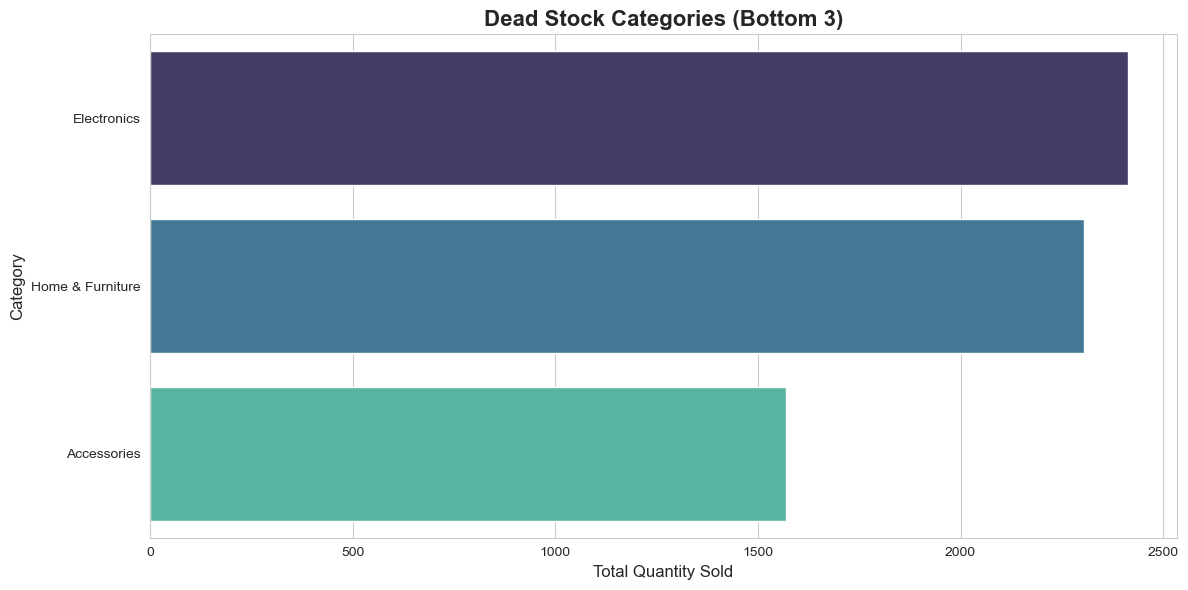

In [35]:

# ========================================
# 2. Dead Stock Categories (Bottom 3 by Quantity)
# ========================================
print("\n" + "="*70)
print("2. DEAD STOCK CATEGORIES (Bottom 3 by Quantity Sold)")
print("="*70)

dead_stock = category_analysis.tail(3)
print(dead_stock)

plt.figure(figsize=(12, 6))
sns.barplot(data=dead_stock, x='total_quantity_sold', y='Category', 
            palette='mako', orient='h')
plt.title('Dead Stock Categories (Bottom 3)', fontsize=16, fontweight='bold')
plt.xlabel('Total Quantity Sold', fontsize=12)
plt.ylabel('Category', fontsize=12)
plt.tight_layout()
plt.show()



3. HIGH PROFIT MARGIN CATEGORIES (Best Performers)
             Category  total_quantity_sold  total_revenue  total_profit  \
0         Accessories                 1570      239816.90      82411.79   
1  Clothing & Apparel                 2970      696190.30     229061.22   
3    Home & Furniture                 2305     1192507.82     276874.31   

   total_orders  avg_profit_margin  velocity  
0           875          34.129624  1.794286  
1          1581          32.700864  1.878558  
3          1279          23.269707  1.802189  


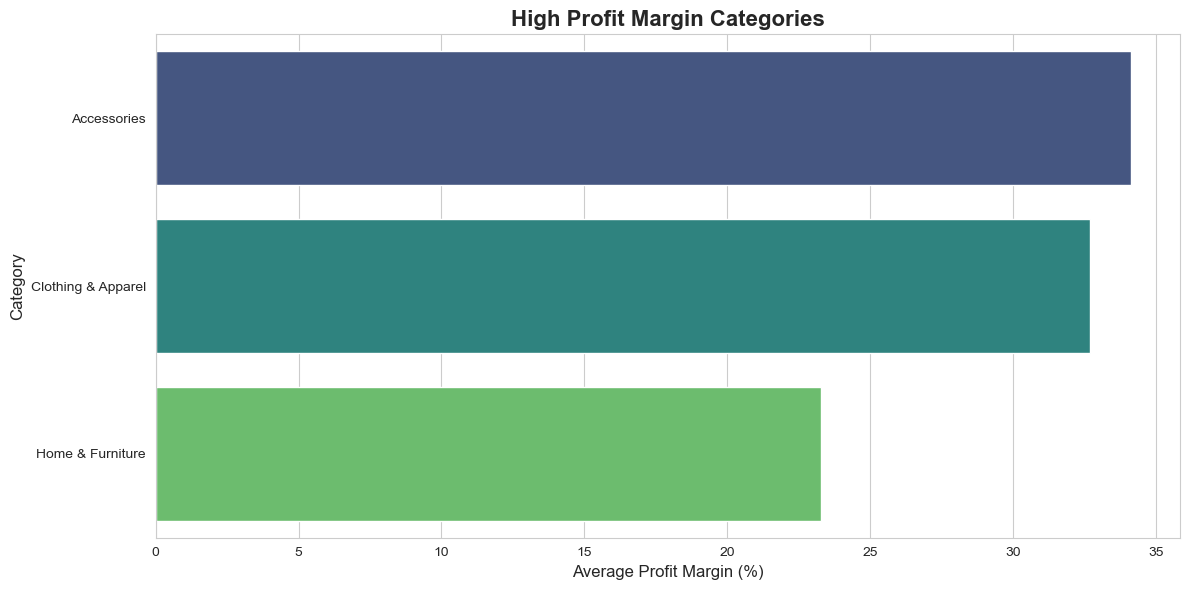


FSN CATEGORY ANALYSIS SUMMARY

=== FSN Classification by Category ===
             Category  total_quantity_sold  velocity  avg_profit_margin  \
1  Clothing & Apparel                 2970  1.878558          32.700864   
2         Electronics                 2414  1.909810          13.979879   
3    Home & Furniture                 2305  1.802189          23.269707   
0         Accessories                 1570  1.794286          34.129624   

     FSN_Class  
1  Fast-Moving  
2  Slow-Moving  
3  Slow-Moving  
0   Dead Stock  


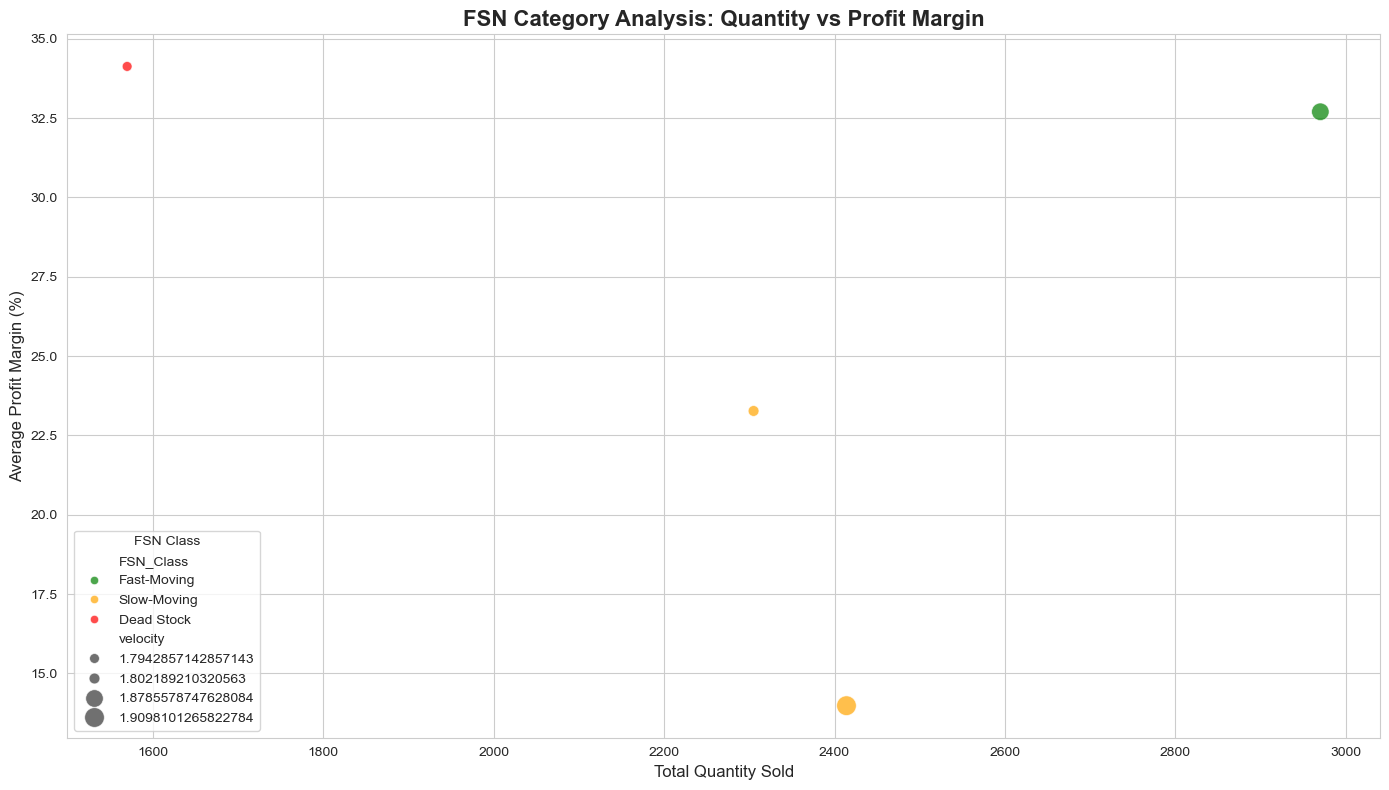

In [36]:

# ========================================
# 3. High Profit Margin Categories (Best Performers)
# ========================================
print("\n" + "="*70)
print("3. HIGH PROFIT MARGIN CATEGORIES (Best Performers)")
print("="*70)

high_margin = category_analysis.sort_values('avg_profit_margin', ascending=False).head(3)
print(high_margin)

plt.figure(figsize=(12, 6))
sns.barplot(data=high_margin, x='avg_profit_margin', y='Category', 
            palette='viridis', orient='h')
plt.title('High Profit Margin Categories', fontsize=16, fontweight='bold')
plt.xlabel('Average Profit Margin (%)', fontsize=12)
plt.ylabel('Category', fontsize=12)
plt.tight_layout()
plt.show()

# ========================================
# Combined FSN Category Visualization
# ========================================
print("\n" + "="*70)
print("FSN CATEGORY ANALYSIS SUMMARY")
print("="*70)

# Define thresholds
fast_threshold = category_analysis['total_quantity_sold'].quantile(0.75)  # Top 25%
slow_threshold = category_analysis['total_quantity_sold'].quantile(0.25)  # Bottom 25%

category_analysis['FSN_Class'] = category_analysis['total_quantity_sold'].apply(
    lambda x: 'Fast-Moving' if x >= fast_threshold else 
              ('Dead Stock' if x <= slow_threshold else 'Slow-Moving')
)

print("\n=== FSN Classification by Category ===")
print(category_analysis[['Category', 'total_quantity_sold', 'velocity', 'avg_profit_margin', 'FSN_Class']])

# Plot FSN Classification
plt.figure(figsize=(14, 8))
sns.scatterplot(data=category_analysis, x='total_quantity_sold', y='avg_profit_margin', 
                hue='FSN_Class', palette={'Fast-Moving': 'green', 'Slow-Moving': 'orange', 'Dead Stock': 'red'},
                size='velocity', sizes=(50, 200), alpha=0.7)
plt.title('FSN Category Analysis: Quantity vs Profit Margin', fontsize=16, fontweight='bold')
plt.xlabel('Total Quantity Sold', fontsize=12)
plt.ylabel('Average Profit Margin (%)', fontsize=12)
plt.legend(title='FSN Class')
plt.tight_layout()
plt.show()